<div>
    <a href="../notebook/__2_data_analysis.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white;">Previous</a>
    <a href="../notebook/__1_business_and_data_understanding.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>

## Section 3.1 | Data Anomaly

In [ ]:
# import required library

# data ETL
from auto_mpg_utils import data_etl
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# anomaly diagnostic & data preprocessing
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

In [2]:
# data ETL
data = data_etl(categorical_variables=['cylinders', 'model_year', 'origin'])

# show first 5 rows of cleaned data
data.head(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


In [45]:
# set random state seed
rng = np.random.RandomState(seed=42)

# split data into random train and test subsets
data_train, data_test = train_test_split(
    data,
    random_state=rng
)

# dimensionality analysis of train-test subsets in DataFrame format
print('Data Dimensionality:')
display(
    pd.DataFrame(
        data=[(data.shape[0], (data.shape[0] / data.shape[0]), data.shape[1]),
              (data_train.shape[0], (data_train.shape[0] / data.shape[0]), data_train.shape[1]),
              (data_test.shape[0], (data_test.shape[0] / data.shape[0]), data_test.shape[1])],
        index=['Whole Data', 'Train Data', 'Test Data'],
        columns=['Row (n)', 'Row Ratio', 'Column']
    )
)

Data Dimensionality:


,Row (n),Row Ratio,Column
Whole Data,392,1.00,8
Train Data,294,0.75,8
Test Data,98,0.25,8


**Observations:**
* *Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
    * *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is by passing a random number generator `RandomState` instance to any of those objects that accept a `random_state` parameter.*
    * *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*
* Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
    * Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
    * `train_test_split` membagi dataset tersebut menjadi `0.75/75%` untuk data train dan `0.25/25%` untuk data test, sesuai default parameter yang diterapkan.
    * Splitting ini hanya membagi jumlah baris, sehingga jumlah kolom `8` adalah sama untuk tiap subset.

---

### Variable Magnitude

In [ ]:
# select variables with numerical data type from train subset
data_train_numerical = pd.DataFrame(data=data_train).select_dtypes(include='number')

# generate descriptive statistics for numerical variables
data_train_numerical.describe()

,displacement,horsepower,weight,acceleration,mpg
count,294.000000,294.000000,294.000000,294.000000,294.000000
mean,195.482993,104.472789,2971.829932,15.507143,23.692177
std,104.656392,38.600221,841.771254,2.856998,8.011347
min,70.000000,46.000000,1613.000000,8.000000,9.000000
25%,105.000000,75.000000,2227.000000,13.500000,17.500000
50%,151.000000,92.500000,2781.500000,15.400000,23.000000
75%,302.000000,129.750000,3625.750000,17.300000,30.000000
max,455.000000,230.000000,5140.000000,24.800000,46.600000


Decriptive statistics di atas menunjukkan perbedaan rentang nilai antar variabel numerik. Magnitude of the variables matter because of the following reasons:
* In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$.
    * If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
    * In addition, in situations where user would estimate the outcome $y$ by contemplating multiple predictors $x_1, x_2, ...x_n$, predictors with greater numeric ranges dominate over those with smaller numeric ranges.
* In Support Vector Machines, feature scaling can decrease the time to find the support vectors.
* Finally, methods using Euclidean distances or distances in general are also affected by the magnitude of the features, as Euclidean distance is sensitive to variations in the magnitude or scales of the predictors. Therefore feature scaling is required for methods that utilise distance calculations like K-Nearest Neighbours.

### Outlier

In [ ]:
def detect_skewed_outlier(data, columns):
    """Function to detect outlier in numerical columns with skewed distribution.

    Args:
        data (DataFrame): dataset to detect the outlier with.
        columns (list-like): list containing names of the numerical columns.
    
    Returns:
        DataFrame: summary of outlier detection in DataFrame format.
    """
    def iqr_outlier_detection(column):
        """Function to detect outlier using interquartile range (IQR).

        Args:
            column (string): name of the numerical column.

        Returns:
            DataFrame: conditional slicing of the data categorized as outlier.
        """
        Q1, Q3 = data[column].quantile(q=0.25), data[column].quantile(q=0.75)
        IQR = Q3 - Q1
        lower_boundary, upper_boundary = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
        outlier = data.loc[(data[column] <  lower_boundary) | (data[column] > upper_boundary)]
    
        return outlier
    
    outlier_summary = pd.DataFrame(
        data={
            'sample': [sorted(iqr_outlier_detection(column)[column].unique()) for column in columns],
            'count': [iqr_outlier_detection(column).shape[0] for column in columns],
            '%': [round(number=iqr_outlier_detection(column).shape[0] / data.shape[0] * 100, ndigits=2) for column in columns],
            'min': [iqr_outlier_detection(column)[column].min() for column in columns],
            'max': [iqr_outlier_detection(column)[column].max() for column in columns]
        },
        index=[column for column in columns]
    )

    return outlier_summary

In [ ]:
# perform outlier detection
detect_skewed_outlier(
    data=data_train_numerical,
    columns=data_train_numerical.columns
)

,sample,count,%,min,max
displacement,[],0,0.00,NaN,NaN
horsepower,"[215.0, 220.0, 225.0, 230.0]",5,1.70,215.0,230.0
weight,[],0,0.00,NaN,NaN
acceleration,"[23.5, 23.7, 24.8]",3,1.02,23.5,24.8
mpg,[],0,0.00,NaN,NaN


### Normality

In [7]:
def normality_diagnostic(data):
    plt.figure(
        figsize=(15, 10),
        layout='constrained'
    )
    for count, feature in enumerate(iterable=data.columns):
        plt.subplot(2, 3, count + 1)
        stats.probplot(data[feature], plot=plt)
        plt.title(label=f"Probability Plot for '{feature}'")

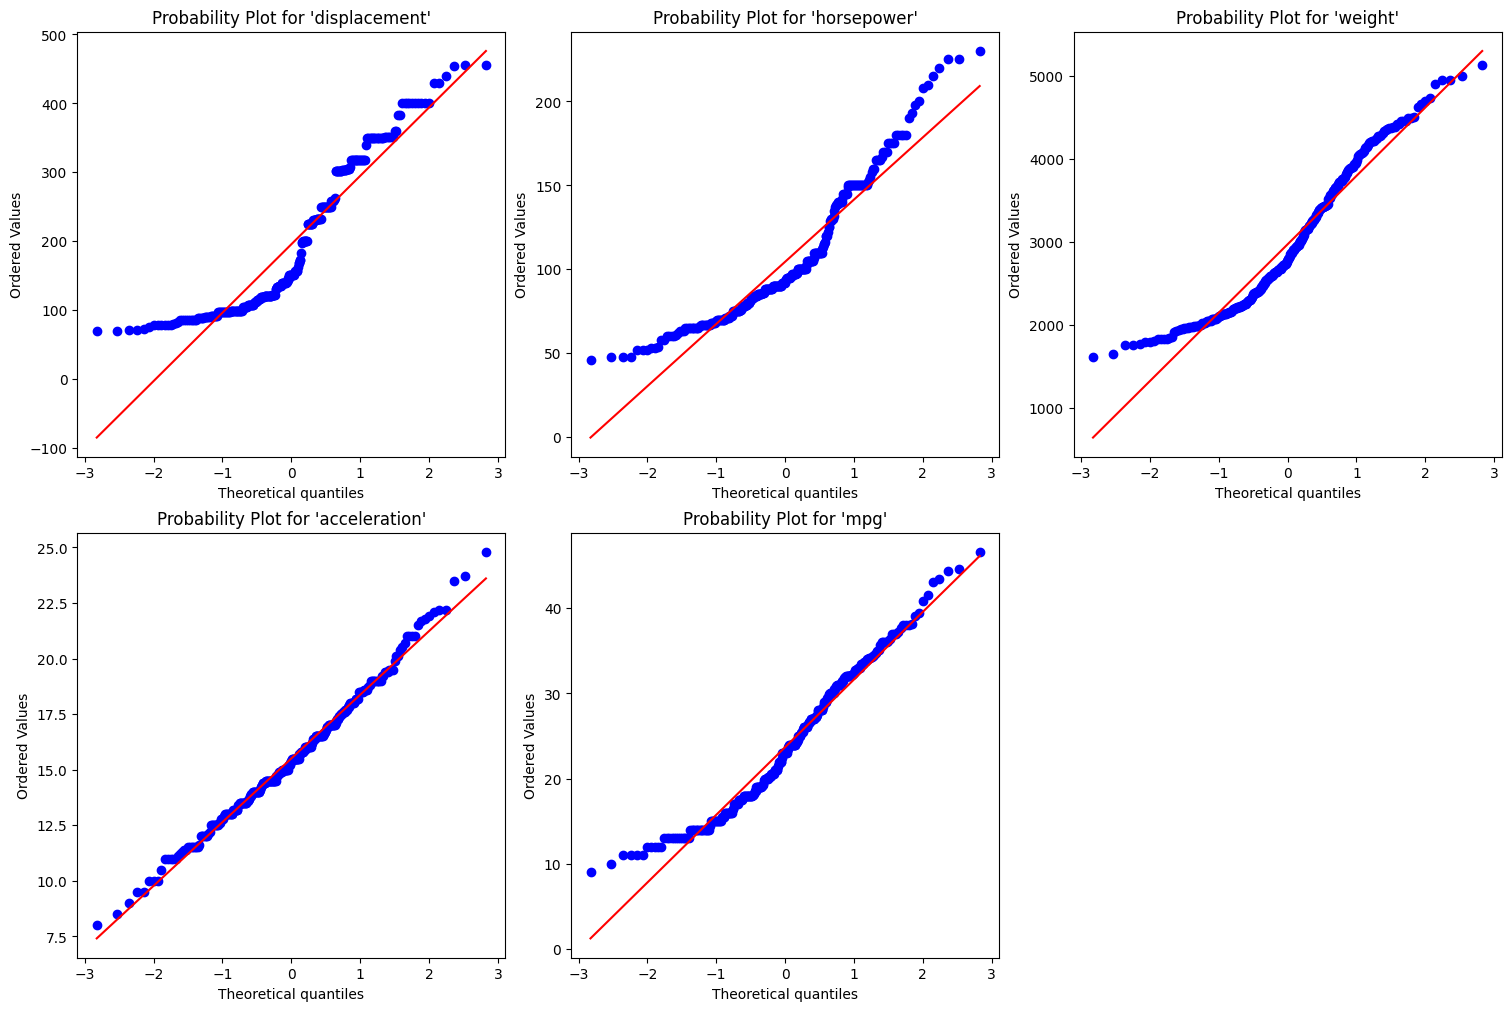

In [8]:
normality_diagnostic(data=data_train_numerical)

### Cardinality

In [9]:
def train_test_labels(train, test, feature):
    train_feature_labels = [label for label in train[feature].unique() if label not in test[feature].unique()]
    test_feature_labels = [label for label in test[feature].unique() if label not in train[feature].unique()]

    print(f"Number of '{feature}' labels present only in the training set: {len(train_feature_labels)}")
    print(f"Number of '{feature}' labels present only in the testing set: {len(test_feature_labels)}")

In [10]:
data_categorical = data.select_dtypes(include='object')

for feature in data_categorical.columns:
    train_test_labels(
        train=data_train,
        test=data_test,
        feature=feature
    )
    print('')

Number of 'cylinders' labels present only in the training set: 1
Number of 'cylinders' labels present only in the testing set: 0

Number of 'model_year' labels present only in the training set: 0
Number of 'model_year' labels present only in the testing set: 0

Number of 'origin' labels present only in the training set: 0
Number of 'origin' labels present only in the testing set: 0



### Rare Label

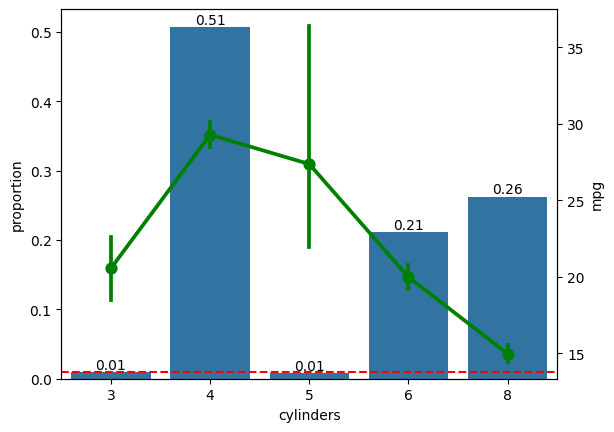

In [11]:
_, ax = plt.subplots()
ax.axhline(
    y=0.01,
    color='red',
    ls='dashed',
)
sns.countplot(
    data=data,
    x='cylinders',
    stat='proportion',
    ax=ax
)
ax.bar_label(
    container=ax.containers[0],
    fmt='%.2f'
)

ax_twinx = ax.twinx()
sns.pointplot(
    data=data,
    x='cylinders',
    y='mpg',
    color='green',
    ax=ax_twinx,
)

plt.show()

In [12]:
train_test_labels(
    train=data_train,
    test=data_test,
    feature='cylinders'
)

Number of 'cylinders' labels present only in the training set: 1
Number of 'cylinders' labels present only in the testing set: 0


In [13]:
train_cylinders_labels = [label for label in data_train['cylinders'].unique() if label not in data_test['cylinders'].unique()]
print(f"'cylinders' labels present only in the training set: {train_cylinders_labels}")

'cylinders' labels present only in the training set: [5]


---

## Section 3.2 | Data Preprocessing

### Drop Feature Labels

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np

class DropLabelsTransformer(BaseEstimator, TransformerMixin):
    """
    Drops rows where specified feature columns contain certain unwanted labels.
    """
    def __init__(self, columns=None, labels_to_drop=None):
        self.columns = columns
        self.labels_to_drop = labels_to_drop

    def fit(self, X, y=None):
        self.feature_names_in_ = X.columns.tolist()
        return self

    def transform(self, X, y=None):
        # Drop rows where any specified column has unwanted values
        mask = X[self.columns].isin(self.labels_to_drop)
        X_transformed = X.loc[~mask].reset_index(drop=True)

        if y is not None:
            y_transformed = y.loc[~mask].reset_index(drop=True)
            return X_transformed, y_transformed

        return X_transformed
    
    def fit_transform(self, X, y=None):
        result = self.fit(X).transform(X)

        if y is not None:
            result = self.fit(X, y).transform(X, y)
            return result
        
        return result
    
    def get_feature_names_out(self, input_features=None):
        input_features = getattr(self, "feature_names_in_")
        return np.array([feature for feature in input_features if feature not in self.labels_to_drop])

In [15]:
drop_labels_transformer = DropLabelsTransformer(
    columns='cylinders',
    labels_to_drop=[3, 5]
)

holdout_train = drop_labels_transformer.fit_transform(X=data_train)
holdout_test = drop_labels_transformer.fit_transform(X=data_test)

In [16]:
features = drop_labels_transformer.get_feature_names_out().tolist()
categorical_features = [feature for feature in features if feature in data_categorical.columns.to_list()]

for feature in categorical_features:
    train_test_labels(
        train=holdout_train,
        test=holdout_test,
        feature=feature
    )
    print('')

Number of 'cylinders' labels present only in the training set: 0
Number of 'cylinders' labels present only in the testing set: 0

Number of 'model_year' labels present only in the training set: 0
Number of 'model_year' labels present only in the testing set: 0

Number of 'origin' labels present only in the training set: 0
Number of 'origin' labels present only in the testing set: 0



### Feature Encoding

In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector

onehot_encoder = OneHotEncoder(
    drop='first',
    sparse_output=False
)

column_transformer = make_column_transformer(
    (onehot_encoder, make_column_selector(dtype_include='object')),
    remainder='drop',
    verbose_feature_names_out=False
)

holdout_train_categorical = pd.DataFrame(
    data=column_transformer.fit_transform(X=holdout_train),
    columns=column_transformer.get_feature_names_out()
)
holdout_test_categorical = pd.DataFrame(
    data=column_transformer.fit_transform(X=holdout_test),
    columns=column_transformer.get_feature_names_out()
)

In [18]:
for feature in column_transformer.get_feature_names_out():
    train_test_labels(
        train=holdout_train_categorical,
        test=holdout_test_categorical,
        feature=feature
    )
    print('')

Number of 'cylinders_6' labels present only in the training set: 0
Number of 'cylinders_6' labels present only in the testing set: 0

Number of 'cylinders_8' labels present only in the training set: 0
Number of 'cylinders_8' labels present only in the testing set: 0

Number of 'model_year_71' labels present only in the training set: 0
Number of 'model_year_71' labels present only in the testing set: 0

Number of 'model_year_72' labels present only in the training set: 0
Number of 'model_year_72' labels present only in the testing set: 0

Number of 'model_year_73' labels present only in the training set: 0
Number of 'model_year_73' labels present only in the testing set: 0

Number of 'model_year_74' labels present only in the training set: 0
Number of 'model_year_74' labels present only in the testing set: 0

Number of 'model_year_75' labels present only in the training set: 0
Number of 'model_year_75' labels present only in the testing set: 0

Number of 'model_year_76' labels present o

### Winsorization

In [19]:
from feature_engine.outliers import Winsorizer

winsorizer = Winsorizer(
    capping_method='iqr',
    tail='right'
)

column_transformer = make_column_transformer(
    (winsorizer, make_column_selector(dtype_include='number')),
    remainder='drop',
    verbose_feature_names_out=False
)

holdout_train = pd.DataFrame(
    data=column_transformer.fit_transform(X=holdout_train),
    columns=column_transformer.get_feature_names_out()
)

detect_skewed_outlier(
    data=holdout_train,
    columns=holdout_train.columns
)

,sample,count,%,min,max
displacement,[],0,0.0,NaN,NaN
horsepower,[],0,0.0,NaN,NaN
weight,[],0,0.0,NaN,NaN
acceleration,[],0,0.0,NaN,NaN
mpg,[],0,0.0,NaN,NaN


### Gaussian Transformation

In [20]:
from sklearn.preprocessing import PowerTransformer

power_transformer = PowerTransformer(method='box-cox')
holdout_train = pd.DataFrame(
    data=power_transformer.fit_transform(X=holdout_train),
    columns=power_transformer.get_feature_names_out()
)

In [21]:
holdout_train.describe()

,displacement,horsepower,weight,acceleration,mpg
count,2.880000e+02,2.880000e+02,2.880000e+02,2.880000e+02,2.880000e+02
mean,-7.648203e-16,-2.775558e-16,-8.857113e-15,7.524845e-16,-6.877215e-16
std,1.001741e+00,1.001741e+00,1.001741e+00,1.001741e+00,1.001741e+00
min,-1.788232e+00,-2.530423e+00,-2.156882e+00,-2.957649e+00,-2.397919e+00
25%,-9.180697e-01,-7.643425e-01,-8.906418e-01,-6.866318e-01,-7.974806e-01
50%,-1.793109e-01,-1.248767e-01,-6.291906e-02,5.539172e-03,4.783090e-02
75%,1.065104e+00,8.424808e-01,8.748979e-01,6.639989e-01,8.401395e-01
max,1.710225e+00,2.001619e+00,1.974923e+00,2.482533e+00,2.262994e+00


In [22]:
def detect_gaussian_outlier(data, columns):

    def std_outlier_detection(column, threshold=3):
        mean, std = data[column].mean(), data[column].std()
        cut_off = std * threshold
        lower_boundary, upper_boundary = mean - cut_off, mean + cut_off
        outlier = data.loc[(data[column] <  (lower_boundary)) | (data[column] > (upper_boundary))]
    
        return outlier
    
    outlier_summary = pd.DataFrame(
        data={
            'sample': [sorted(std_outlier_detection(column)[column].unique()) for column in columns],
            'count': [std_outlier_detection(column).shape[0] for column in columns],
            '%': [round(number=std_outlier_detection(column).shape[0] / data.shape[0] * 100, ndigits=2) for column in columns],
            'min': [std_outlier_detection(column)[column].min() for column in columns],
            'max': [std_outlier_detection(column)[column].max() for column in columns]
        },
        index=[column for column in columns]
    )

    return outlier_summary

In [23]:
detect_gaussian_outlier(
    data=holdout_train,
    columns=holdout_train.columns
)

,sample,count,%,min,max
displacement,[],0,0.0,NaN,NaN
horsepower,[],0,0.0,NaN,NaN
weight,[],0,0.0,NaN,NaN
acceleration,[],0,0.0,NaN,NaN
mpg,[],0,0.0,NaN,NaN


### Preprocessing Pipeline

In [24]:
from sklearn.pipeline import make_pipeline

data_train = drop_labels_transformer.fit_transform(X=data_train)
data_test = drop_labels_transformer.fit_transform(X=data_test)

column_winsorizer = make_column_transformer(
    (winsorizer, make_column_selector(dtype_include='number')),
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

column_transformer = make_column_transformer(
    (onehot_encoder, make_column_selector(dtype_include='object')),
    (power_transformer, make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
)

preprocessing_pipeline = make_pipeline(
    column_winsorizer,
    column_transformer
)

holdout_train = pd.DataFrame(
    data=preprocessing_pipeline.fit_transform(X=data_train),
    columns=preprocessing_pipeline.get_feature_names_out()
)

---

## Section 3.3 | Model Assumption

### Normality

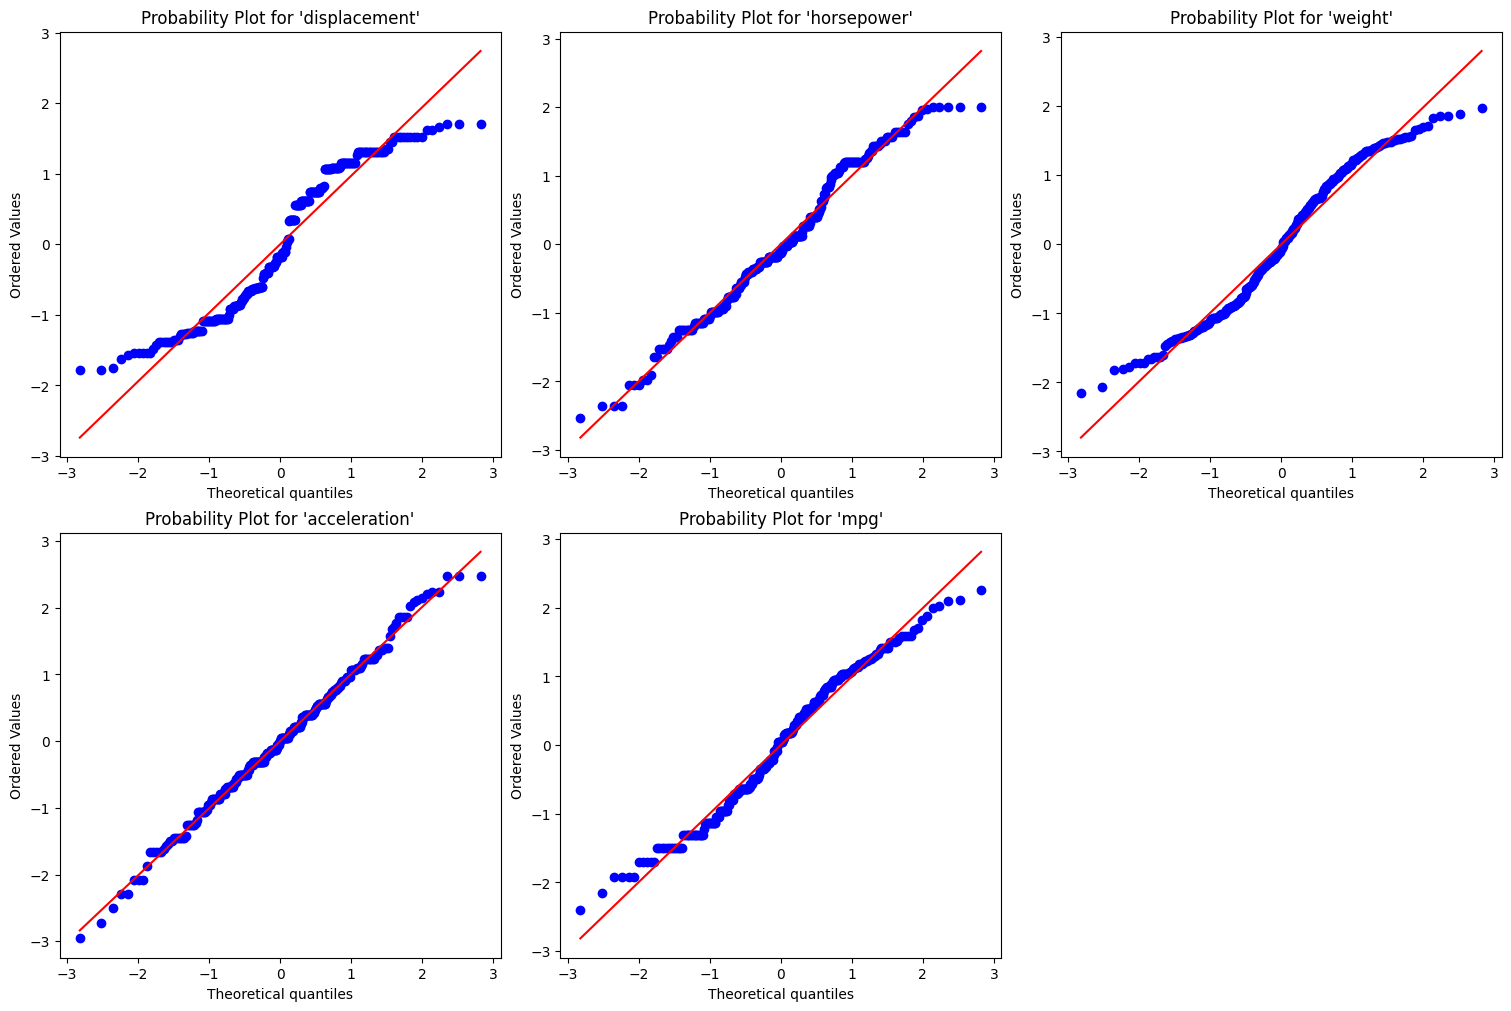

In [25]:
holdout_train_numerical = holdout_train.filter(items=data_train_numerical.columns)

normality_diagnostic(data=holdout_train_numerical)

### Linearity

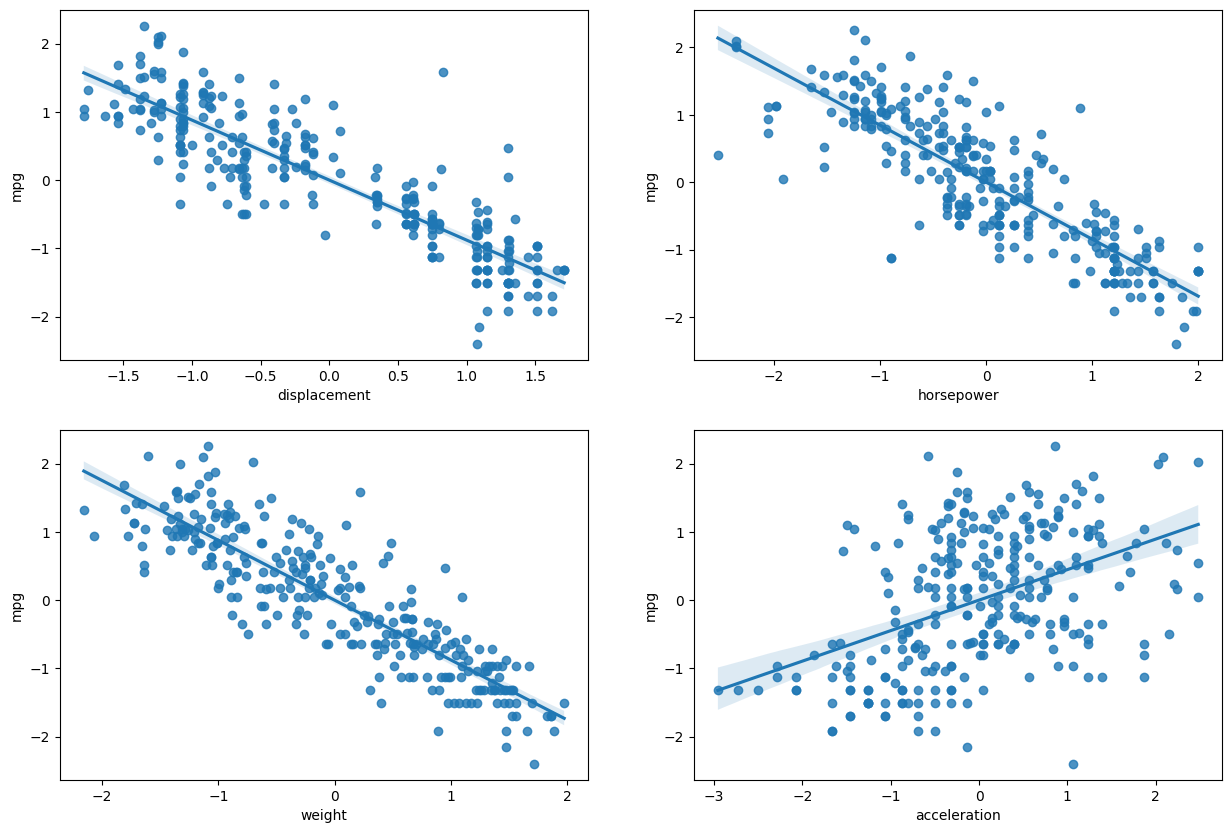

In [26]:
plt.figure(figsize=(15, 10))
for count, column in enumerate(iterable=holdout_train_numerical.drop(columns='mpg').columns):
    plt.subplot(2, 2, count + 1)
    sns.regplot(
        data=holdout_train_numerical,
        x=column,
        y='mpg'
    )

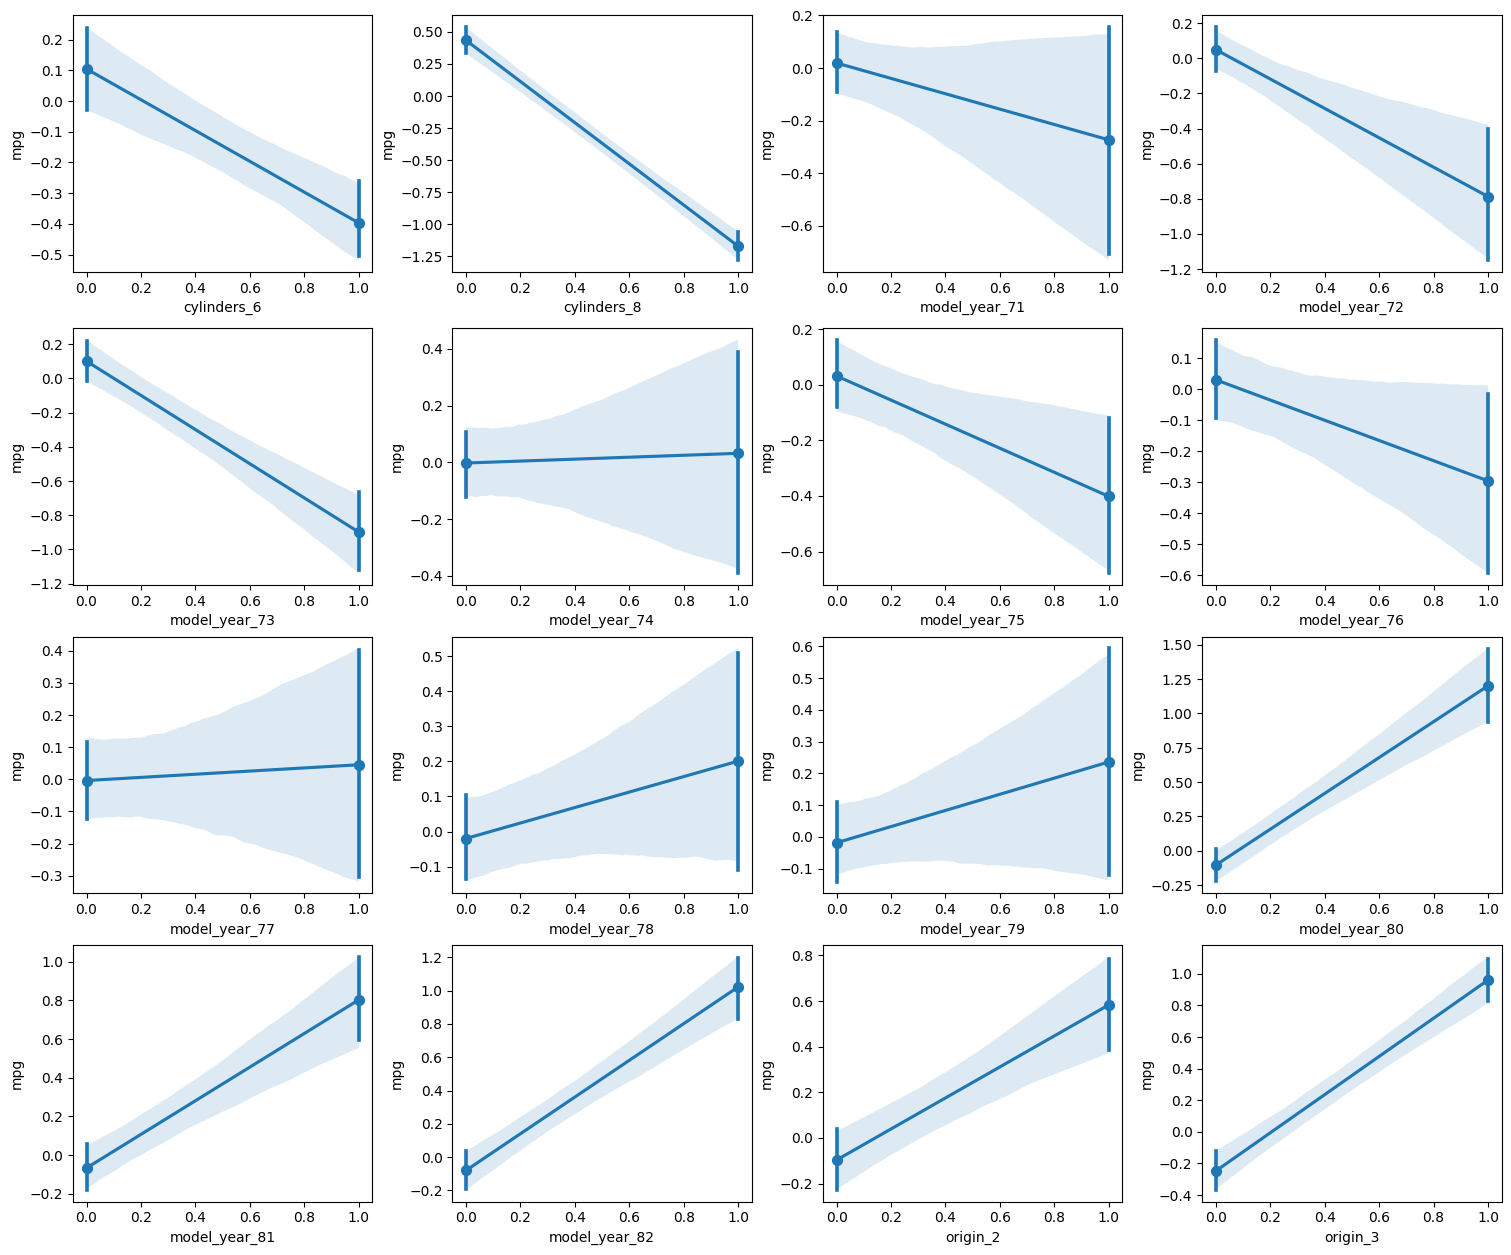

In [27]:
holdout_train_categorical_mpg = holdout_train.loc[:, ~holdout_train.columns.isin(values=holdout_train_numerical.columns.drop(labels='mpg'))]

plt.figure(
    figsize=(15, 15),
    layout='constrained'
)
for count, column in enumerate(iterable=holdout_train_categorical_mpg.drop(columns='mpg').columns):
    plt.subplot(5, 4, count + 1)
    sns.regplot(
        data=holdout_train_categorical_mpg,
        x=column,
        x_estimator=np.mean,
        y='mpg'
    )

### Multicollinearity

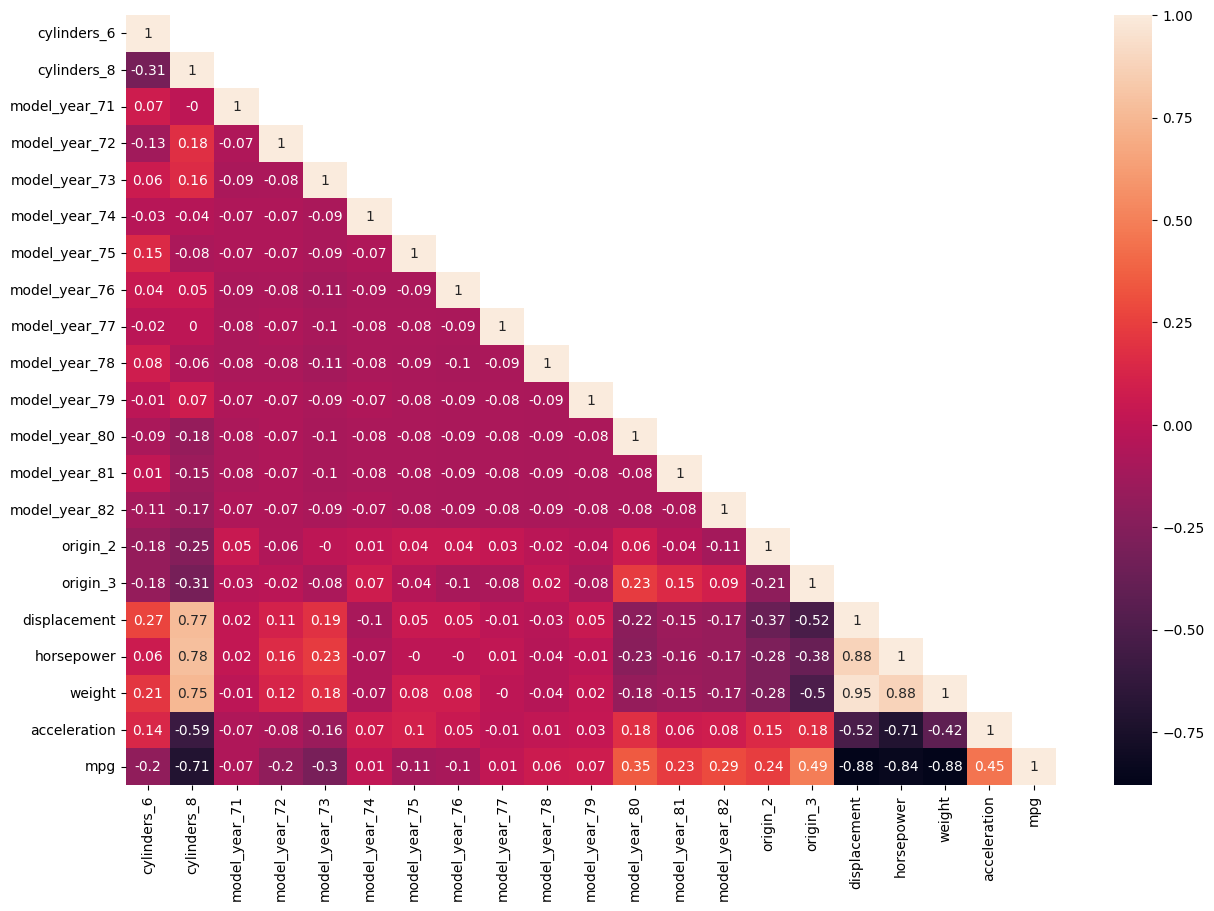

In [28]:
correlation_matrix = holdout_train.corr().round(decimals=2)

mask = np.triu(np.ones_like(a=correlation_matrix))
np.fill_diagonal(
    a=mask,
    val=False
)

plt.figure(figsize=(15, 10))

axes = sns.heatmap(
    data=correlation_matrix, 
    annot=True,
    mask=mask
)

plt.show()

In [29]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

holdout_train = add_constant(data=holdout_train.drop(columns='mpg'))

pd.DataFrame(
    data=[variance_inflation_factor(holdout_train.values, i) for i in range(holdout_train.shape[1])],
    index=holdout_train.columns,
    columns=['vif']
)

,vif
const,26.785178
cylinders_6,4.870626
cylinders_8,10.823672
model_year_71,1.886528
model_year_72,1.809895
model_year_73,2.228982
model_year_74,2.070352
model_year_75,2.205724
model_year_76,2.418062
model_year_77,2.090197


### Heteroscedasticity

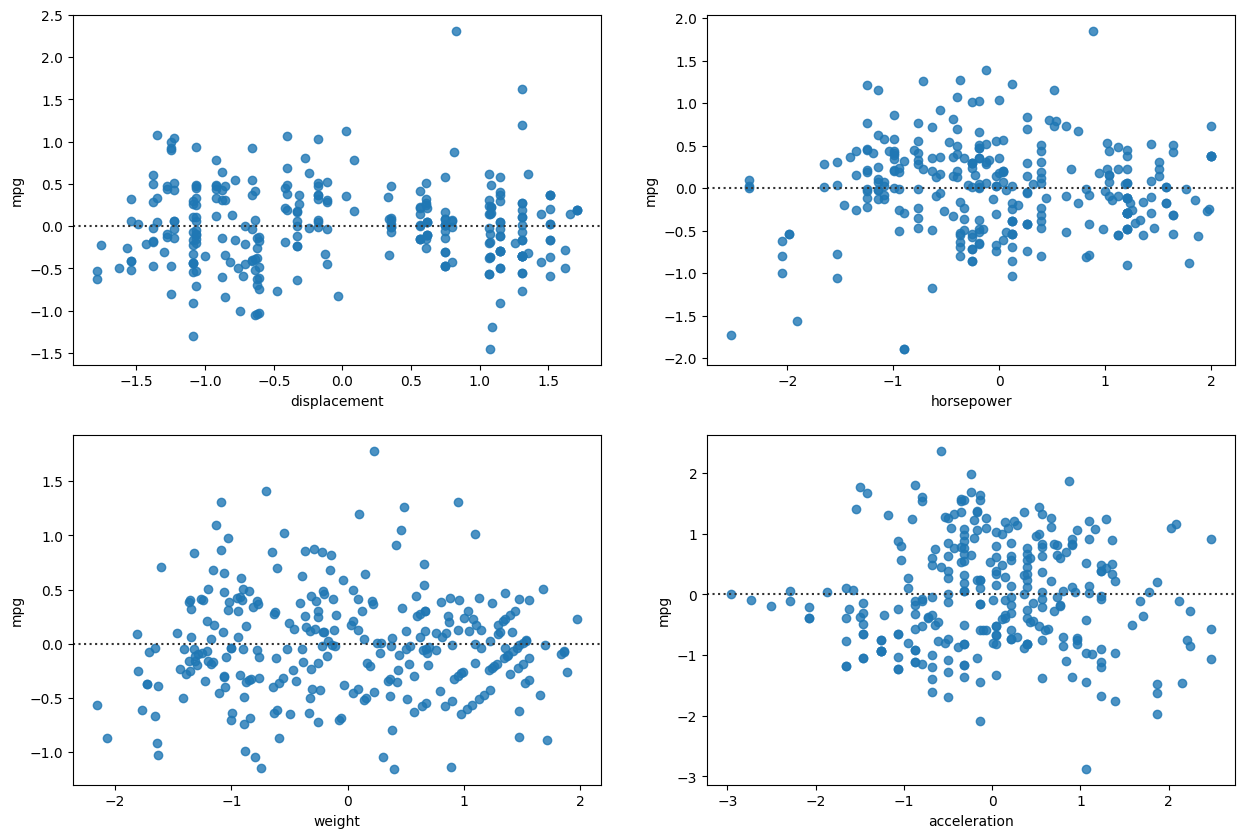

In [30]:
plt.figure(figsize=(15, 10))
for count, column in enumerate(iterable=holdout_train_numerical.drop(columns='mpg').columns):
    plt.subplot(2, 2, count + 1)
    sns.residplot(
        data=holdout_train_numerical,
        x=column,
        y='mpg'
    )

## Feature Interaction

In [31]:
class RatioInteractionTransformer(BaseEstimator, TransformerMixin):
    """
    Create ratio features between specified numeric column pairs and converts those to numeric dtypes.
    Automatically drops all original columns used in those ratios.
    """

    def __init__(self, ratios=None):
        """
        Parameters
        ----------
        ratios : list of tuple
            Each tuple defines (numerator, denominator).
        """
        self.ratios = ratios

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):

        used_cols = set()
        for num, den in self.ratios:
            ratio_name = f"{num}_div_{den}"
            X[ratio_name] = (X[num] / X[den]).apply(func=pd.to_numeric)
            used_cols.update([num, den])

        # Always drop original ratio source columns
        X = X.drop(columns=list(used_cols))

        self.feature_names_out_ = list(X.columns)
        return X

    def get_feature_names_out(self, input_features=None):
        return getattr(self, "feature_names_out_", self.feature_names_in_)

In [32]:
ratio_interaction_transformer = RatioInteractionTransformer(
    ratios=[
        ('displacement', 'cylinders'),
        ('horsepower', 'weight')
    ]
)

In [33]:
data_train = drop_labels_transformer.fit_transform(X=data_train)

column_winsorizer = make_column_transformer(
    (winsorizer, make_column_selector(dtype_include='number')),
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

column_transformer = make_column_transformer(
    (onehot_encoder, make_column_selector(dtype_include='object')),
    (power_transformer, make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
)

preprocessing_pipeline = make_pipeline(
    ratio_interaction_transformer,
    column_winsorizer,
    column_transformer
)

train_transformed = pd.DataFrame(
    data=preprocessing_pipeline.fit_transform(X=data_train),
    columns=preprocessing_pipeline.get_feature_names_out()
)

In [34]:
features = np.array(ratio_interaction_transformer.get_feature_names_out()).tolist()
numerical_features = [feature for feature in features if feature not in categorical_features]
train_transformed_numerical = train_transformed.filter(items=numerical_features)

train_transformed_numerical.describe()

,acceleration,mpg,displacement_div_cylinders,horsepower_div_weight
count,2.880000e+02,2.880000e+02,2.880000e+02,2.880000e+02
mean,7.524845e-16,-6.877215e-16,4.317534e-17,-2.615192e-15
std,1.001741e+00,1.001741e+00,1.001741e+00,1.001741e+00
min,-2.957649e+00,-2.397919e+00,-2.066267e+00,-2.800021e+00
25%,-6.866318e-01,-7.974806e-01,-8.472239e-01,-6.487525e-01
50%,5.539172e-03,4.783090e-02,1.361752e-01,-4.321623e-02
75%,6.639989e-01,8.401395e-01,7.216728e-01,6.388423e-01
max,2.482533e+00,2.262994e+00,2.351558e+00,2.374871e+00


In [35]:
detect_gaussian_outlier(
    data=train_transformed_numerical,
    columns=train_transformed_numerical.columns
)

,sample,count,%,min,max
acceleration,[],0,0.0,NaN,NaN
mpg,[],0,0.0,NaN,NaN
displacement_div_cylinders,[],0,0.0,NaN,NaN
horsepower_div_weight,[],0,0.0,NaN,NaN


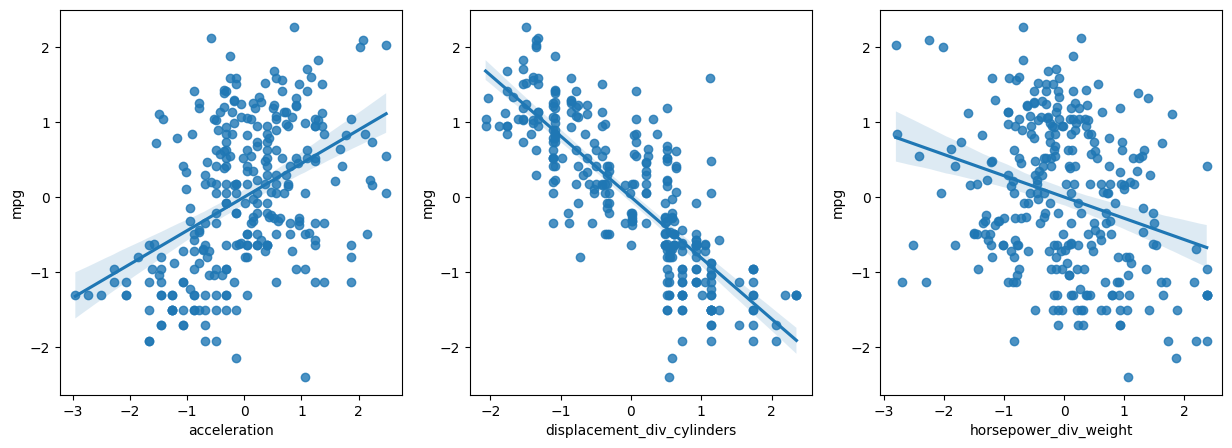

In [36]:
plt.figure(figsize=(15, 5))
for count, column in enumerate(iterable=train_transformed_numerical.drop(columns='mpg').columns):
    plt.subplot(1, 3, count + 1)
    sns.regplot(
        data=train_transformed_numerical,
        x=column,
        y='mpg'
    )

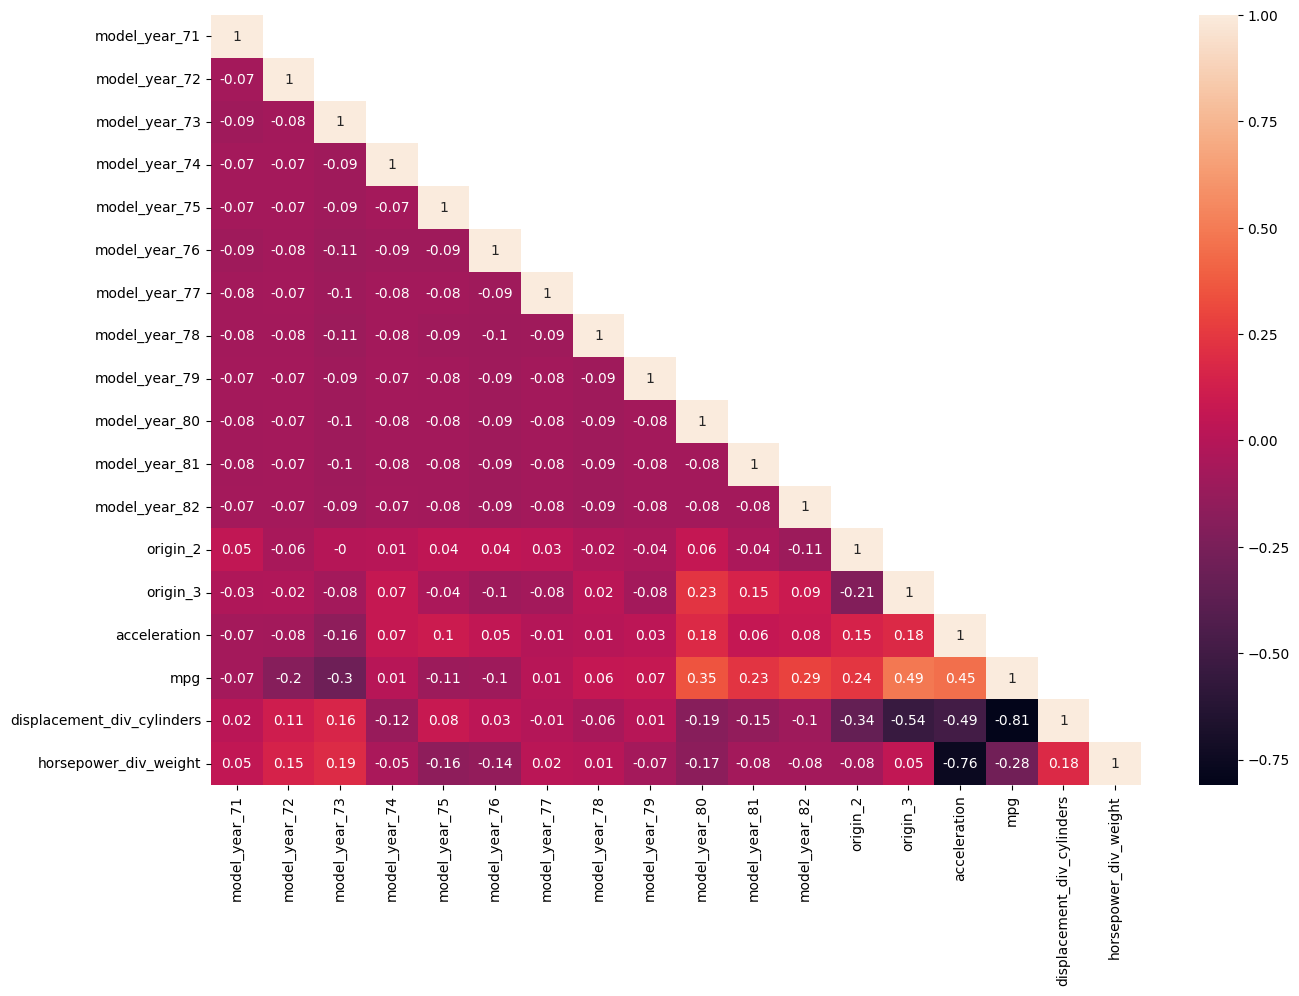

In [37]:
correlation_matrix = train_transformed.corr().round(decimals=2)

mask = np.triu(np.ones_like(a=correlation_matrix))
np.fill_diagonal(
    a=mask,
    val=False
)

plt.figure(figsize=(15, 10))

axes = sns.heatmap(
    data=correlation_matrix, 
    annot=True,
    mask=mask
)

plt.show()

In [38]:
train_transformed = add_constant(data=train_transformed.drop(columns='mpg'))

pd.DataFrame(
    data=[variance_inflation_factor(train_transformed.values, i) for i in range(train_transformed.shape[1])],
    index=train_transformed.columns,
    columns=['vif']
)

,vif
const,17.902226
model_year_71,1.897687
model_year_72,1.752964
model_year_73,2.197384
model_year_74,2.049661
model_year_75,2.150311
model_year_76,2.429429
model_year_77,2.068097
model_year_78,2.297933
model_year_79,2.105858
